In [2]:
import pandas as pd 

In [8]:
df = pd.read_csv(r"C:\Users\DELL\OneDrive\Desktop\customer-churn-ml\data\raw\customer_churn.csv")

In [9]:
df

,Customer_ID,Age,Gender,Location,Tenure_Months,Monthly_Charges,Total_Charges,Subscription_Type,Payment_Method,Login_Frequency,Support_Tickets,Complaints,Discount_Received,Contract_Type,Last_Login_Days,Usage_Hours,Customer_Satisfaction,Churn
0,CUST10001,22,Male,Pune,17,1902.78,32226.17,Basic,Credit Card,17,0,1,No,Quarterly,11,48.3,5.0,1
1,CUST10002,59,Male,Chennai,26,2489.35,63164.14,Standard,Credit Card,13,1,0,No,Yearly,15,18.6,7.1,0
2,CUST10003,52,Female,Mumbai,62,293.25,17398.45,Premium,UPI,20,1,1,Yes,Monthly,2,64.0,4.9,0
3,CUST10004,41,Female,Chennai,8,762.31,6087.82,Basic,UPI,9,3,1,No,Monthly,25,24.5,6.7,1
4,CUST10005,40,Male,Hyderabad,8,1573.80,13139.40,Basic,UPI,12,2,0,Yes,Monthly,32,40.8,7.6,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,CUST19996,42,Male,Pune,61,1892.20,120738.31,Premium,Net Banking,9,2,1,No,Quarterly,7,24.8,4.3,1
9996,CUST19997,70,Male,Ahmedabad,18,1459.04,25312.24,Premium,Credit Card,11,1,1,No,Quarterly,20,45.2,NaN,1
9997,CUST19998,36,Male,Delhi,49,1580.60,82169.82,Standard,UPI,16,2,0,No,Quarterly,13,69.6,10.0,1
9998,CUST19999,47,Male,Chennai,3,2436.46,7256.01,Basic,Net Banking,10,1,0,No,Yearly,17,34.4,7.8,1


# Data Understanding

In [4]:
#Number of records 
len(df)

10000

In [5]:
#Number of features 
len(df.columns)

18

In [6]:
#Numberical Columns 
df.columns

Index(['Customer_ID', 'Age', 'Gender', 'Location', 'Tenure_Months',
       'Monthly_Charges', 'Total_Charges', 'Subscription_Type',
       'Payment_Method', 'Login_Frequency', 'Support_Tickets', 'Complaints',
       'Discount_Received', 'Contract_Type', 'Last_Login_Days', 'Usage_Hours',
       'Customer_Satisfaction', 'Churn'],
      dtype='str')

In [7]:
#Categorical Columns 
df.select_dtypes(include="object").columns

C:\Users\DELL\AppData\Local\Temp\ipykernel_20968\1107208828.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").columns


Index(['Customer_ID', 'Gender', 'Location', 'Subscription_Type',
       'Payment_Method', 'Discount_Received', 'Contract_Type'],
      dtype='str')

In [8]:
#Target variable
df["Churn"].value_counts()

Churn
1    5780
0    4220
Name: count, dtype: int64

In [9]:
#Missing Values 
df.isnull().sum()

Customer_ID                0
Age                        0
Gender                     0
Location                   0
Tenure_Months              0
Monthly_Charges          100
Total_Charges              0
Subscription_Type          0
Payment_Method             0
Login_Frequency            0
Support_Tickets            0
Complaints                 0
Discount_Received          0
Contract_Type              0
Last_Login_Days            0
Usage_Hours              100
Customer_Satisfaction    100
Churn                      0
dtype: int64

In [10]:
#Duplicate Records 
df.duplicated().sum()

np.int64(0)

In [11]:
#Outliears 
df.describe()

,Age,Tenure_Months,Monthly_Charges,Total_Charges,Login_Frequency,Support_Tickets,Complaints,Last_Login_Days,Usage_Hours,Customer_Satisfaction,Churn
count,10000.000000,10000.000000,9900.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,9900.000000,9900.000000,10000.000000
mean,43.804400,36.504900,1353.787783,49404.930584,12.014800,1.501900,0.709200,11.854400,35.192727,6.953727,0.578000
std,15.224826,20.921939,663.708501,39825.688568,5.917473,1.223334,0.854347,11.986107,17.384849,1.747440,0.493903
min,18.000000,1.000000,199.110000,203.720000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,31.000000,18.000000,779.710000,16936.115000,8.000000,1.000000,0.000000,3.000000,23.000000,5.700000,0.000000
50%,44.000000,37.000000,1351.335000,38560.090000,12.000000,1.000000,1.000000,8.000000,34.900000,7.000000,1.000000
75%,57.000000,55.000000,1939.357500,73665.472500,16.000000,2.000000,1.000000,17.000000,47.000000,8.200000,1.000000
max,70.000000,72.000000,2498.960000,190535.320000,37.000000,8.000000,6.000000,149.000000,100.600000,10.000000,1.000000


In [12]:
#Data type
df.dtypes

Customer_ID                  str
Age                        int64
Gender                       str
Location                     str
Tenure_Months              int64
Monthly_Charges          float64
Total_Charges            float64
Subscription_Type            str
Payment_Method               str
Login_Frequency            int64
Support_Tickets            int64
Complaints                 int64
Discount_Received            str
Contract_Type                str
Last_Login_Days            int64
Usage_Hours              float64
Customer_Satisfaction    float64
Churn                      int64
dtype: object

# Data Cleaning 

In [13]:
#Missing values 
df.isnull().sum()

Customer_ID                0
Age                        0
Gender                     0
Location                   0
Tenure_Months              0
Monthly_Charges          100
Total_Charges              0
Subscription_Type          0
Payment_Method             0
Login_Frequency            0
Support_Tickets            0
Complaints                 0
Discount_Received          0
Contract_Type              0
Last_Login_Days            0
Usage_Hours              100
Customer_Satisfaction    100
Churn                      0
dtype: int64

In [14]:
#Demographic information 
df[["Age", "Gender", "Location"]].isnull().sum()

Age         0
Gender      0
Location    0
dtype: int64

In [15]:
#Filling the missing values
#Monthly_Charges
df["Monthly_Charges"] = df["Monthly_Charges"].fillna(
    df["Monthly_Charges"].median()
)

In [16]:
#Usage Hours 
df["Usage_Hours"] = df["Usage_Hours"].fillna(
    df["Usage_Hours"].median()
)

In [17]:
#Customer Satisfaction
df["Customer_Satisfaction"] = df["Customer_Satisfaction"].fillna(
    df["Customer_Satisfaction"].median()
)

In [18]:
df.isnull().sum()

Customer_ID              0
Age                      0
Gender                   0
Location                 0
Tenure_Months            0
Monthly_Charges          0
Total_Charges            0
Subscription_Type        0
Payment_Method           0
Login_Frequency          0
Support_Tickets          0
Complaints               0
Discount_Received        0
Contract_Type            0
Last_Login_Days          0
Usage_Hours              0
Customer_Satisfaction    0
Churn                    0
dtype: int64

In [19]:
#Duplicate Customers
#Customer ID
df["Customer_ID"].duplicated().sum()

np.int64(0)

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
#Invalid Values 
#Age 
(df["Age"] < 0).sum()

np.int64(0)

In [22]:
#Monthly Charges 
(df["Monthly_Charges"] < 0).sum()

np.int64(0)

In [23]:
#Tenure
(df["Tenure_Months"] < 0).sum()

np.int64(0)

In [24]:
#Satisfaction 
(
    (df["Customer_Satisfaction"] < 1) |
    (df["Customer_Satisfaction"] > 10)
).sum()

np.int64(0)

# Exploratory Data Analysis (EDA)

In [25]:
#Tenure 
#Average tenure by churn 
df.groupby("Churn")["Tenure_Months"].mean()

Churn
0    37.544550
1    35.745848
Name: Tenure_Months, dtype: float64

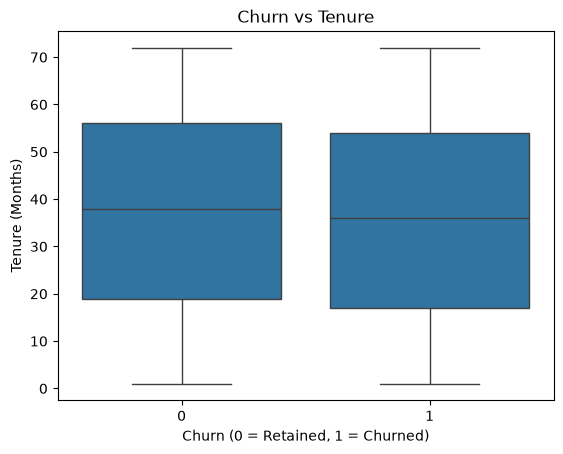

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x="Churn", y="Tenure_Months", data=df)

plt.title("Churn vs Tenure")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Tenure (Months)")
plt.show()

In [27]:
#Monthly Charges 
df.groupby("Churn")["Monthly_Charges"].mean()

Churn
0     765.394351
1    1783.333631
Name: Monthly_Charges, dtype: float64

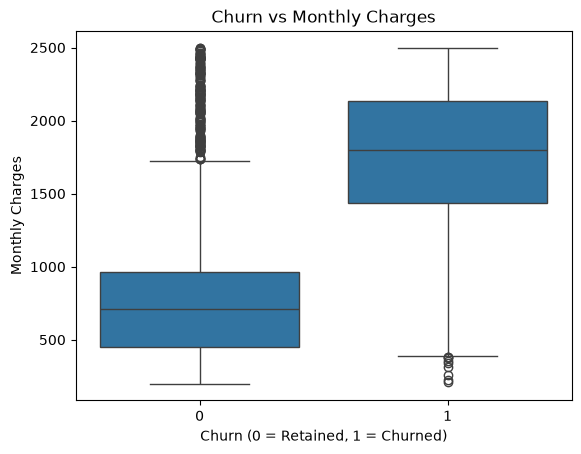

In [28]:
sns.boxplot(x="Churn", y="Monthly_Charges", data=df)

plt.title("Churn vs Monthly Charges")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Monthly Charges")
plt.show()

In [29]:
#Support Tickets
df.groupby("Churn")["Support_Tickets"].mean()

Churn
0    1.485308
1    1.514014
Name: Support_Tickets, dtype: float64

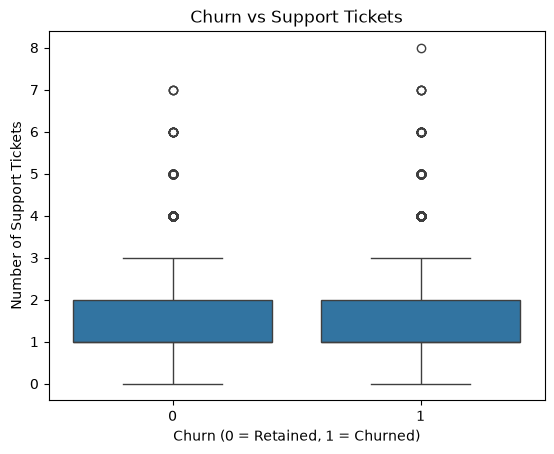

In [30]:
sns.boxplot(x="Churn", y="Support_Tickets", data=df)

plt.title("Churn vs Support Tickets")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Support Tickets")
plt.show()

In [31]:
# Complaints
df.groupby("Churn")["Complaints"].mean()

Churn
0    0.705687
1    0.711765
Name: Complaints, dtype: float64

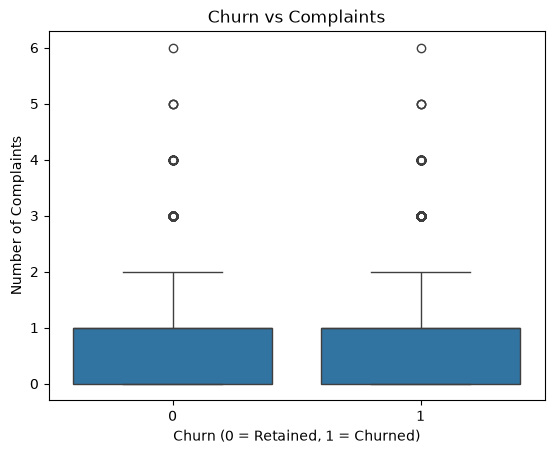

In [32]:
sns.boxplot(x="Churn", y="Complaints", data=df)

plt.title("Churn vs Complaints")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Complaints")
plt.show()

In [33]:
#Login Frequency
df.groupby("Churn")["Login_Frequency"].mean()

Churn
0    12.077014
1    11.969377
Name: Login_Frequency, dtype: float64

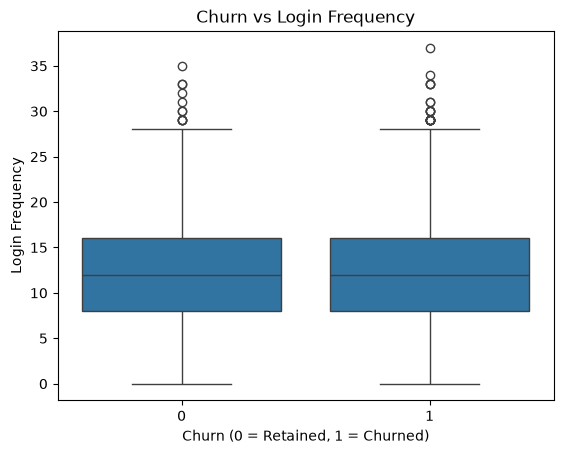

In [34]:
sns.boxplot(x="Churn", y="Login_Frequency", data=df)

plt.title("Churn vs Login Frequency")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Login Frequency")
plt.show()

In [35]:
#Satisfaction 
df.groupby("Churn")["Customer_Satisfaction"].mean()

Churn
0    7.034005
1    6.895917
Name: Customer_Satisfaction, dtype: float64

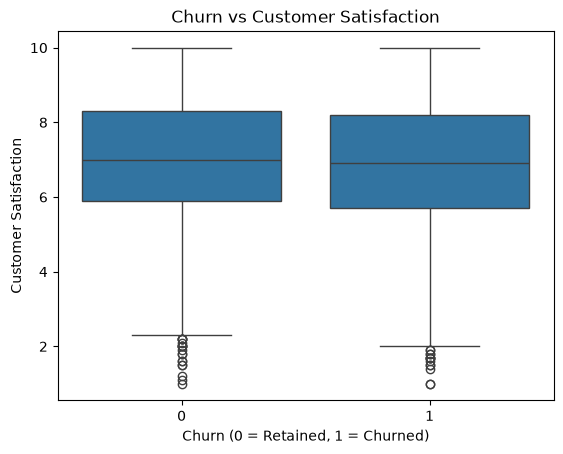

In [36]:
sns.boxplot(x="Churn", y="Customer_Satisfaction", data=df)

plt.title("Churn vs Customer Satisfaction")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Customer Satisfaction")
plt.show()

# Required Visualizations

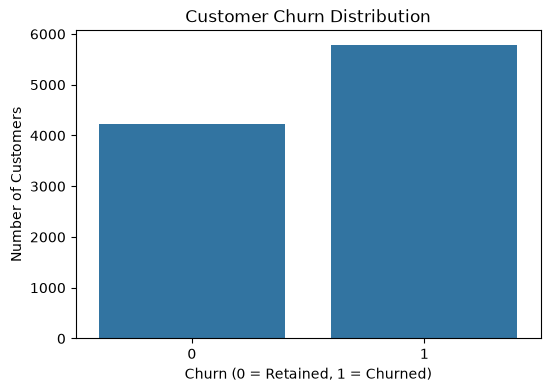

In [37]:
#Churn Distribution 
plt.figure(figsize=(6, 4))

sns.countplot(x="Churn", data=df)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")

plt.show()

In [38]:
#Churn by Subscription Type
churn_by_subscription = df.groupby("Subscription_Type")["Churn"].mean() * 100

print(churn_by_subscription)

Subscription_Type
Basic       58.571790
Premium     55.750879
Standard    58.054187
Name: Churn, dtype: float64


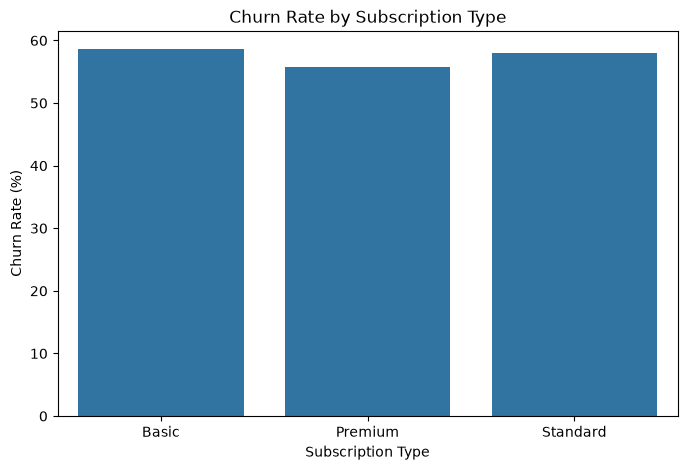

In [39]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=churn_by_subscription.index,
    y=churn_by_subscription.values
)

plt.title("Churn Rate by Subscription Type")
plt.xlabel("Subscription Type")
plt.ylabel("Churn Rate (%)")

plt.show()

In [40]:
#Churn by Contract Type
churn_by_contract = df.groupby("Contract_Type")["Churn"].mean() * 100

print(churn_by_contract)

Contract_Type
Monthly      58.771930
Quarterly    56.422380
Yearly       57.236304
Name: Churn, dtype: float64


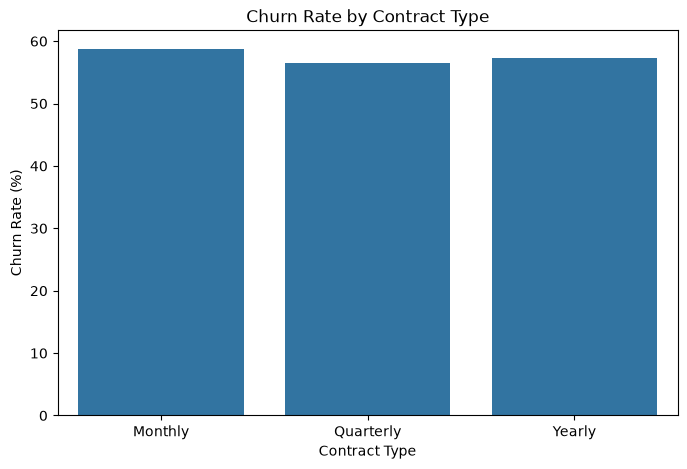

In [41]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=churn_by_contract.index,
    y=churn_by_contract.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

In [42]:
#Churn by Location
churn_by_location = df.groupby("Location")["Churn"].mean() * 100

print(churn_by_location)

Location
Ahmedabad    55.086072
Bangalore    57.971014
Chennai      58.419792
Delhi        57.095980
Hyderabad    57.852564
Kolkata      57.927786
Mumbai       59.782609
Pune         58.263773
Name: Churn, dtype: float64


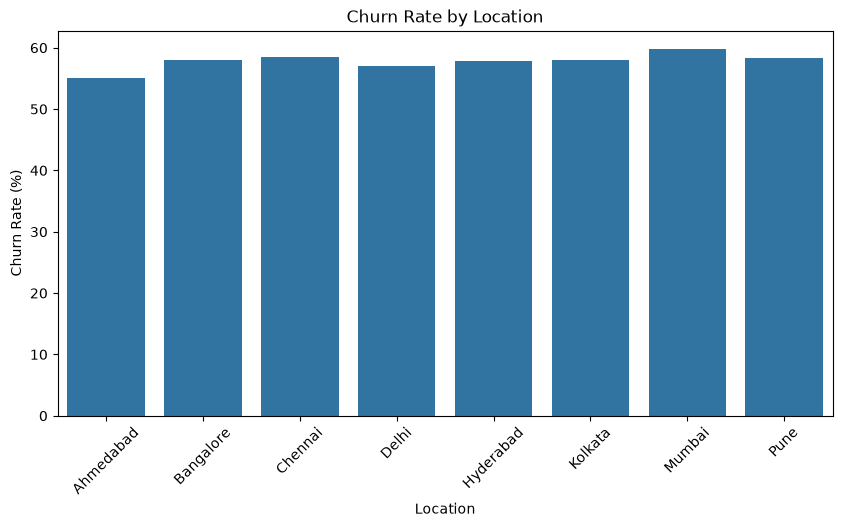

In [43]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=churn_by_location.index,
    y=churn_by_location.values
)

plt.title("Churn Rate by Location")
plt.xlabel("Location")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)

plt.show()

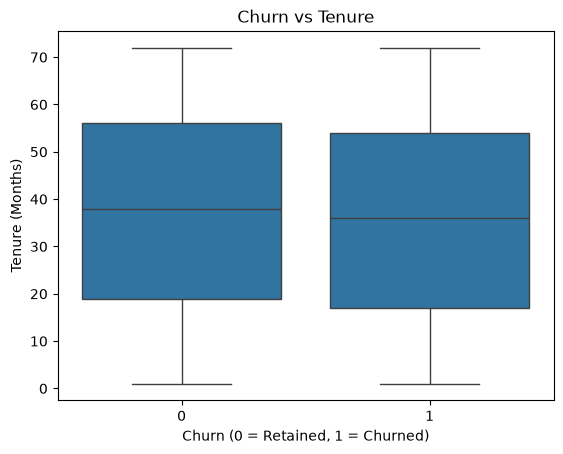

In [44]:
#Churn vs Tenure
sns.boxplot(x="Churn", y="Tenure_Months", data=df)

plt.title("Churn vs Tenure")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Tenure (Months)")
plt.show()

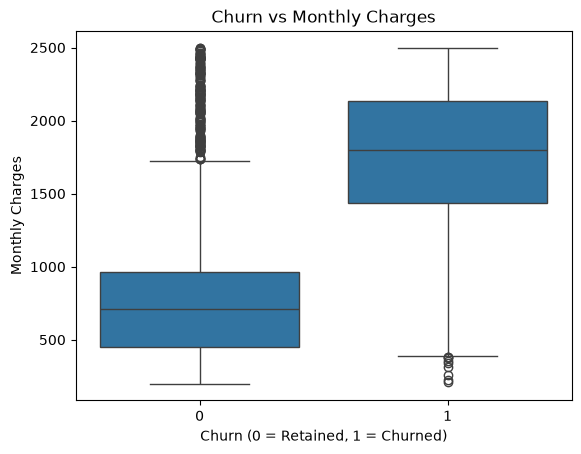

In [45]:
#Churn vs Monthly Charges
sns.boxplot(x="Churn", y="Monthly_Charges", data=df)

plt.title("Churn vs Monthly Charges")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Monthly Charges")
plt.show()

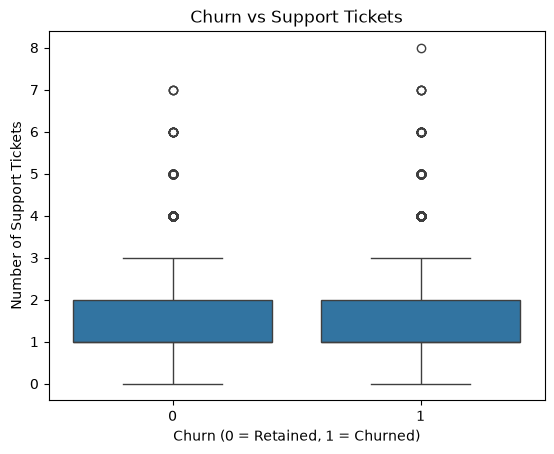

In [46]:
#Churn vs Support Tickets
sns.boxplot(x="Churn", y="Support_Tickets", data=df)

plt.title("Churn vs Support Tickets")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Support Tickets")
plt.show()

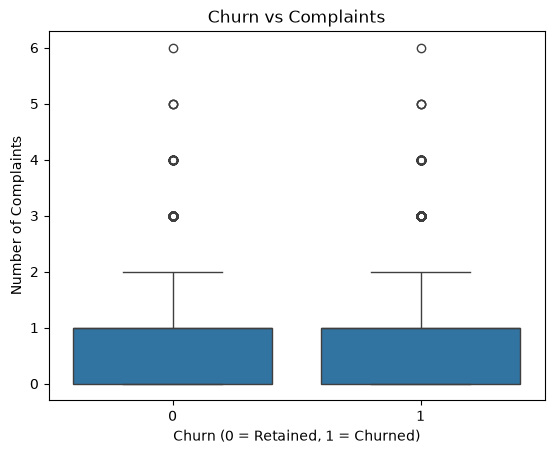

In [47]:
#Churn vs Customer Satisfaction
sns.boxplot(x="Churn", y="Complaints", data=df)

plt.title("Churn vs Complaints")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Complaints")
plt.show()

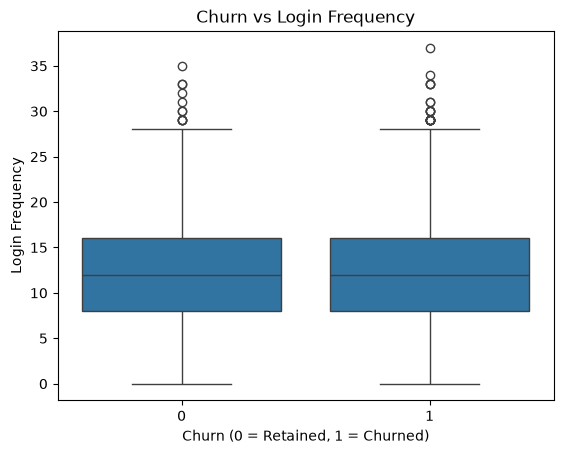

In [48]:
# Churn vs Login Frequency
sns.boxplot(x="Churn", y="Login_Frequency", data=df)

plt.title("Churn vs Login Frequency")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Login Frequency")
plt.show()

In [49]:
#Correlation Heatmap
correlation = df.select_dtypes(include="number").drop(
    columns=["Customer_ID"],
    errors="ignore"
).corr()

print(correlation["Churn"].sort_values(ascending=False))

Churn                    1.000000
Monthly_Charges          0.761323
Total_Charges            0.439950
Last_Login_Days          0.055860
Support_Tickets          0.011590
Complaints               0.003513
Usage_Hours             -0.004832
Age                     -0.005100
Login_Frequency         -0.008984
Customer_Satisfaction   -0.039226
Tenure_Months           -0.042462
Name: Churn, dtype: float64


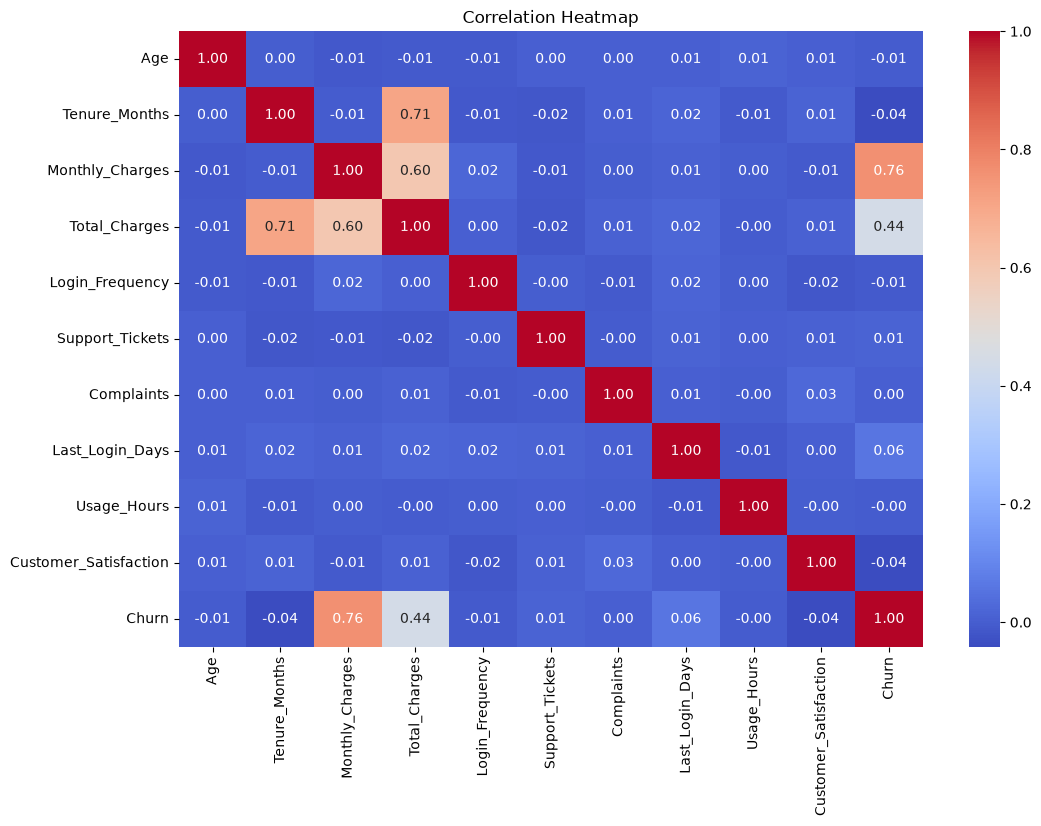

In [50]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

# Customer Behavior Analysis


In [51]:
#risk score
df["Risk_Score"] = (
    (df["Usage_Hours"] < 20).astype(int)
    + (df["Complaints"] >= 2).astype(int)
    + (df["Support_Tickets"] >= 3).astype(int)
    + (df["Customer_Satisfaction"] < 5).astype(int)
    + (df["Last_Login_Days"] > 30).astype(int)
)

df[["Customer_ID", "Risk_Score"]].head()

,Customer_ID,Risk_Score
0,CUST10001,0
1,CUST10002,1
2,CUST10003,1
3,CUST10004,1
4,CUST10005,1


In [52]:
#warning signals 
df["Risk_Score"].value_counts().sort_index()

Risk_Score
0    4344
1    3956
2    1433
3     251
4      16
Name: count, dtype: int64

In [53]:
#Behavior_Risk
df["Behavior_Risk"] = df["Risk_Score"].apply(
    lambda x: "Low Risk" if x == 0
    else "Medium Risk" if x <= 2
    else "High Risk"
)

In [54]:
df["Behavior_Risk"].value_counts()

Behavior_Risk
Medium Risk    5389
Low Risk       4344
High Risk       267
Name: count, dtype: int64

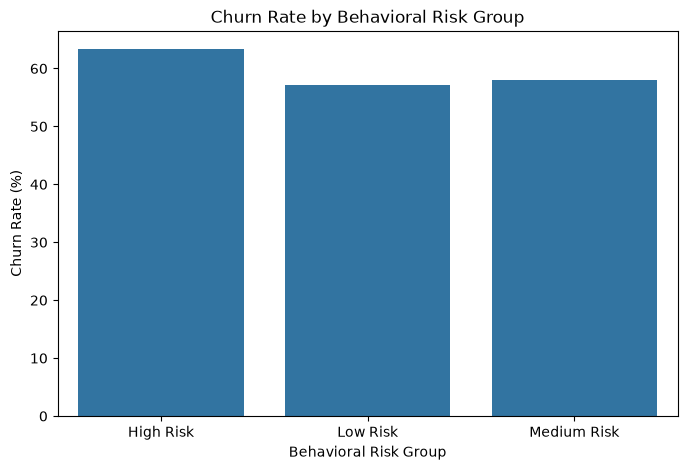

In [55]:
risk_churn = df.groupby("Behavior_Risk")["Churn"].mean() * 100

plt.figure(figsize=(8, 5))

sns.barplot(
    x=risk_churn.index,
    y=risk_churn.values
)

plt.title("Churn Rate by Behavioral Risk Group")
plt.xlabel("Behavioral Risk Group")
plt.ylabel("Churn Rate (%)")

plt.show()

In [56]:
df.groupby("Behavior_Risk")["Churn"].mean() * 100

Behavior_Risk
High Risk      63.295880
Low Risk       57.205341
Medium Risk    58.007051
Name: Churn, dtype: float64

In [57]:
risk_signals = pd.DataFrame({
    "Low_Usage": df["Usage_Hours"] < 20,
    "High_Complaints": df["Complaints"] >= 2,
    "High_Support_Tickets": df["Support_Tickets"] >= 3,
    "Low_Satisfaction": df["Customer_Satisfaction"] < 5,
    "Recent_Inactivity": df["Last_Login_Days"] > 30
})

print(risk_signals.sum())

Low_Usage               1966
High_Complaints         1624
High_Support_Tickets    1939
Low_Satisfaction        1329
Recent_Inactivity        781
dtype: int64


# Feature Engineering

In [58]:
df["Customer_Lifetime_Value"] = (
    df["Monthly_Charges"] * df["Tenure_Months"]
)

In [59]:
#Customer_Lifetime_Value
df[[
    "Customer_ID",
    "Monthly_Charges",
    "Tenure_Months",
    "Customer_Lifetime_Value"
]].head()

,Customer_ID,Monthly_Charges,Tenure_Months,Customer_Lifetime_Value
0,CUST10001,1902.78,17,32347.26
1,CUST10002,2489.35,26,64723.10
2,CUST10003,293.25,62,18181.50
3,CUST10004,762.31,8,6098.48
4,CUST10005,1573.80,8,12590.40


In [60]:
#Engagement Score
df["Engagement_Score"] = (
    (df["Login_Frequency"] >= 12).astype(int)
    + (df["Usage_Hours"] >= 35).astype(int)
    + (df["Last_Login_Days"] <= 30).astype(int)
)

In [61]:
df[[
    "Customer_ID",
    "Login_Frequency",
    "Usage_Hours",
    "Last_Login_Days",
    "Engagement_Score"
]].head()

,Customer_ID,Login_Frequency,Usage_Hours,Last_Login_Days,Engagement_Score
0,CUST10001,17,48.3,11,3
1,CUST10002,13,18.6,15,2
2,CUST10003,20,64.0,2,3
3,CUST10004,9,24.5,25,1
4,CUST10005,12,40.8,32,2


In [62]:
df["Engagement_Score"].value_counts().sort_index()

Engagement_Score
0     171
1    2617
2    4813
3    2399
Name: count, dtype: int64

In [63]:
#Support_Risk
df["Support_Risk"] = (
    (df["Support_Tickets"] >= 3).astype(int)
    + (df["Complaints"] >= 2).astype(int)
)

In [64]:
df[[
    "Customer_ID",
    "Support_Tickets",
    "Complaints",
    "Support_Risk"
]].head()

,Customer_ID,Support_Tickets,Complaints,Support_Risk
0,CUST10001,0,1,0
1,CUST10002,1,0,0
2,CUST10003,1,1,0
3,CUST10004,3,1,1
4,CUST10005,2,0,0


In [65]:
df["Support_Risk"].value_counts().sort_index()

Support_Risk
0    6753
1    2931
2     316
Name: count, dtype: int64

In [66]:
#Inactivity_Flag
df["Inactivity_Flag"] = (
    df["Last_Login_Days"] > 30
).astype(int)

In [67]:
df[[
    "Customer_ID",
    "Last_Login_Days",
    "Inactivity_Flag"
]].head()

,Customer_ID,Last_Login_Days,Inactivity_Flag
0,CUST10001,11,0
1,CUST10002,15,0
2,CUST10003,2,0
3,CUST10004,25,0
4,CUST10005,32,1


In [68]:
df["Inactivity_Flag"].value_counts()

Inactivity_Flag
0    9219
1     781
Name: count, dtype: int64

# Categorical Data Encoding

In [69]:
categorical_cols = [
    "Gender",
    "Location",
    "Subscription_Type",
    "Payment_Method",
    "Discount_Received",
    "Contract_Type"
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())


Gender:
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

Location:
<StringArray>
[     'Pune',   'Chennai',    'Mumbai', 'Hyderabad', 'Bangalore',     'Delhi',
 'Ahmedabad',   'Kolkata']
Length: 8, dtype: str

Subscription_Type:
<StringArray>
['Basic', 'Standard', 'Premium']
Length: 3, dtype: str

Payment_Method:
<StringArray>
['Credit Card', 'UPI', 'Cash', 'Net Banking', 'Debit Card']
Length: 5, dtype: str

Discount_Received:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

Contract_Type:
<StringArray>
['Quarterly', 'Yearly', 'Monthly']
Length: 3, dtype: str


In [70]:
categorical_cols = [
    "Gender",
    "Location",
    "Subscription_Type",
    "Payment_Method",
    "Discount_Received",
    "Contract_Type"
]

df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True
)

In [71]:
df_encoded.head()

,Customer_ID,Age,Tenure_Months,Monthly_Charges,Total_Charges,Login_Frequency,Support_Tickets,Complaints,Last_Login_Days,Usage_Hours,...,Location_Pune,Subscription_Type_Premium,Subscription_Type_Standard,Payment_Method_Credit Card,Payment_Method_Debit Card,Payment_Method_Net Banking,Payment_Method_UPI,Discount_Received_Yes,Contract_Type_Quarterly,Contract_Type_Yearly
0,CUST10001,22,17,1902.78,32226.17,17,0,1,11,48.3,...,True,False,False,True,False,False,False,False,True,False
1,CUST10002,59,26,2489.35,63164.14,13,1,0,15,18.6,...,False,False,True,True,False,False,False,False,False,True
2,CUST10003,52,62,293.25,17398.45,20,1,1,2,64.0,...,False,True,False,False,False,False,True,True,False,False
3,CUST10004,41,8,762.31,6087.82,9,3,1,25,24.5,...,False,False,False,False,False,False,True,False,False,False
4,CUST10005,40,8,1573.80,13139.40,12,2,0,32,40.8,...,False,False,False,False,False,False,True,True,False,False


In [72]:
print("Original columns:", len(df.columns))
print("Encoded columns:", len(df_encoded.columns))

Original columns: 24
Encoded columns: 35


In [73]:
print(df_encoded.columns.tolist())

['Customer_ID', 'Age', 'Tenure_Months', 'Monthly_Charges', 'Total_Charges', 'Login_Frequency', 'Support_Tickets', 'Complaints', 'Last_Login_Days', 'Usage_Hours', 'Customer_Satisfaction', 'Churn', 'Risk_Score', 'Behavior_Risk', 'Customer_Lifetime_Value', 'Engagement_Score', 'Support_Risk', 'Inactivity_Flag', 'Gender_Male', 'Location_Bangalore', 'Location_Chennai', 'Location_Delhi', 'Location_Hyderabad', 'Location_Kolkata', 'Location_Mumbai', 'Location_Pune', 'Subscription_Type_Premium', 'Subscription_Type_Standard', 'Payment_Method_Credit Card', 'Payment_Method_Debit Card', 'Payment_Method_Net Banking', 'Payment_Method_UPI', 'Discount_Received_Yes', 'Contract_Type_Quarterly', 'Contract_Type_Yearly']


#  Feature Scaling

In [74]:
numerical_cols = df_encoded.select_dtypes(
    include=["int64", "float64"]
).columns

print(numerical_cols.tolist())

['Age', 'Tenure_Months', 'Monthly_Charges', 'Total_Charges', 'Login_Frequency', 'Support_Tickets', 'Complaints', 'Last_Login_Days', 'Usage_Hours', 'Customer_Satisfaction', 'Churn', 'Risk_Score', 'Customer_Lifetime_Value', 'Engagement_Score', 'Support_Risk', 'Inactivity_Flag']


In [75]:
features_to_scale = [
    "Age",
    "Tenure_Months",
    "Monthly_Charges",
    "Total_Charges",
    "Login_Frequency",
    "Support_Tickets",
    "Complaints",
    "Last_Login_Days",
    "Usage_Hours",
    "Customer_Satisfaction",
    "Customer_Lifetime_Value"
]

In [76]:
from sklearn.preprocessing import StandardScaler

In [77]:
scaler = StandardScaler()

In [78]:
df_scaled = df_encoded.copy()

In [79]:
df_scaled[features_to_scale] = scaler.fit_transform(
    df_scaled[features_to_scale]
)

In [80]:
df_scaled[features_to_scale].head()

,Age,Tenure_Months,Monthly_Charges,Total_Charges,Login_Frequency,Support_Tickets,Complaints,Last_Login_Days,Usage_Hours,Customer_Satisfaction,Customer_Lifetime_Value
0,-1.432233,-0.932317,0.831405,-0.431370,0.842496,-1.227772,0.340394,-0.071286,0.757953,-1.124003,-0.428897
1,0.998130,-0.502125,1.719678,0.345503,0.166498,-0.410293,-0.830149,0.262450,-0.959122,0.083866,0.388215
2,0.538332,1.218643,-1.605991,-0.803704,1.349495,-0.410293,0.340394,-0.822193,1.665632,-1.181520,-0.786418
3,-0.184208,-1.362509,-0.895669,-1.087722,-0.509500,1.224665,0.340394,1.096791,-0.618020,-0.146204,-1.091373
4,-0.249894,-1.362509,0.333213,-0.910652,-0.002501,0.407186,-0.830149,1.680830,0.324348,0.371454,-0.927528


In [81]:
print(df_scaled[features_to_scale].mean())

Age                       -7.531753e-17
Tenure_Months              3.552714e-17
Monthly_Charges            2.376765e-16
Total_Charges             -4.121148e-17
Login_Frequency            1.421085e-16
Support_Tickets           -4.618528e-17
Complaints                -6.536993e-17
Last_Login_Days            7.105427e-18
Usage_Hours                1.023182e-16
Customer_Satisfaction      1.918465e-16
Customer_Lifetime_Value    1.111999e-16
dtype: float64


In [82]:
print(df_scaled[features_to_scale].std())

Age                        1.00005
Tenure_Months              1.00005
Monthly_Charges            1.00005
Total_Charges              1.00005
Login_Frequency            1.00005
Support_Tickets            1.00005
Complaints                 1.00005
Last_Login_Days            1.00005
Usage_Hours                1.00005
Customer_Satisfaction      1.00005
Customer_Lifetime_Value    1.00005
dtype: float64


# Train/Test Split

In [86]:
X = df_scaled.drop(columns=["Churn"])
y = df_scaled["Churn"]

In [87]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [88]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8000, 34)
X_test: (2000, 34)
y_train: (8000,)
y_test: (2000,)


In [89]:
print("Training Churn Distribution:")
print(y_train.value_counts())

print("\nTesting Churn Distribution:")
print(y_test.value_counts())

Training Churn Distribution:
Churn
1    4624
0    3376
Name: count, dtype: int64

Testing Churn Distribution:
Churn
1    1156
0     844
Name: count, dtype: int64


# Machine Learning Models

In [92]:
X = df_scaled.drop(columns=["Churn", "Customer_ID", "Behavior_Risk"])
y = df_scaled["Churn"]

In [93]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 32)
Testing data: (2000, 32)


In [94]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [95]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [96]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


#  Model Evaluation

In [99]:
# Generate predictions for all three models

y_pred_logistic = logistic_model.predict(X_test)
y_pred_tree = decision_tree_model.predict(X_test)
y_pred_forest = random_forest_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [100]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Logistic Regression
print("Logistic Regression")
print("Accuracy :", accuracy_score(y_test, y_pred_logistic))
print("Precision:", precision_score(y_test, y_pred_logistic))
print("Recall   :", recall_score(y_test, y_pred_logistic))
print("F1 Score :", f1_score(y_test, y_pred_logistic))

# Decision Tree
print("\nDecision Tree")
print("Accuracy :", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall   :", recall_score(y_test, y_pred_tree))
print("F1 Score :", f1_score(y_test, y_pred_tree))

# Random Forest
print("\nRandom Forest")
print("Accuracy :", accuracy_score(y_test, y_pred_forest))
print("Precision:", precision_score(y_test, y_pred_forest))
print("Recall   :", recall_score(y_test, y_pred_forest))
print("F1 Score :", f1_score(y_test, y_pred_forest))

Logistic Regression
Accuracy : 0.9215
Precision: 0.9294926913155632
Recall   : 0.9351211072664359
F1 Score : 0.9322984044846917

Decision Tree
Accuracy : 0.8665
Precision: 0.8828596037898363
Recall   : 0.8866782006920415
F1 Score : 0.8847647820457488

Random Forest
Accuracy : 0.922
Precision: 0.9173622704507512
Recall   : 0.9506920415224913
F1 Score : 0.9337298215802888


In [101]:
from sklearn.metrics import confusion_matrix

cm_logistic = confusion_matrix(y_test, y_pred_logistic)
cm_tree = confusion_matrix(y_test, y_pred_tree)
cm_forest = confusion_matrix(y_test, y_pred_forest)

print("Logistic Regression Confusion Matrix:")
print(cm_logistic)

print("\nDecision Tree Confusion Matrix:")
print(cm_tree)

print("\nRandom Forest Confusion Matrix:")
print(cm_forest)

Logistic Regression Confusion Matrix:
[[ 762   82]
 [  75 1081]]

Decision Tree Confusion Matrix:
[[ 708  136]
 [ 131 1025]]

Random Forest Confusion Matrix:
[[ 745   99]
 [  57 1099]]


In [102]:
from sklearn.metrics import roc_auc_score

# Get probability of churn (class 1)
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]
y_prob_forest = random_forest_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
roc_logistic = roc_auc_score(y_test, y_prob_logistic)
roc_tree = roc_auc_score(y_test, y_prob_tree)
roc_forest = roc_auc_score(y_test, y_prob_forest)

print("Logistic Regression ROC-AUC:", roc_logistic)
print("Decision Tree ROC-AUC:", roc_tree)
print("Random Forest ROC-AUC:", roc_forest)

Logistic Regression ROC-AUC: 0.9529212925761328
Decision Tree ROC-AUC: 0.8627703799668739
Random Forest ROC-AUC: 0.95360134226537


# Model Comparison

In [103]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        0.9215,
        0.8665,
        0.9220
    ],
    "Precision": [
        0.9295,
        0.8829,
        0.9174
    ],
    "Recall": [
        0.9351,
        0.8867,
        0.9507
    ],
    "F1 Score": [
        0.9323,
        0.8848,
        0.9337
    ],
    "ROC-AUC": [
        0.9529,
        0.8628,
        0.9536
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9215,0.9295,0.9351,0.9323,0.9529
1,Decision Tree,0.8665,0.8829,0.8867,0.8848,0.8628
2,Random Forest,0.9220,0.9174,0.9507,0.9337,0.9536


In [104]:
comparison_display = model_comparison.copy()

for col in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    comparison_display[col] = (
        comparison_display[col] * 100
    ).round(2).astype(str) + "%"

comparison_display["ROC-AUC"] = comparison_display["ROC-AUC"].round(4)

comparison_display

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,92.15%,92.95%,93.51%,93.23%,0.9529
1,Decision Tree,86.65%,88.29%,88.67%,88.48%,0.8628
2,Random Forest,92.2%,91.74%,95.07%,93.37%,0.9536


#  Feature Importance

In [105]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
2,Monthly_Charges,0.507132
3,Total_Charges,0.098114
11,Customer_Lifetime_Value,0.098034
1,Tenure_Months,0.080345
8,Usage_Hours,0.026049
9,Customer_Satisfaction,0.024293
7,Last_Login_Days,0.023531
0,Age,0.023282
4,Login_Frequency,0.021603
5,Support_Tickets,0.010378


In [106]:
top_features = feature_importance.head(10)

print("Top 10 Features Influencing Churn:")
print(top_features)

Top 10 Features Influencing Churn:
                    Feature  Importance
2           Monthly_Charges    0.507132
3             Total_Charges    0.098114
11  Customer_Lifetime_Value    0.098034
1             Tenure_Months    0.080345
8               Usage_Hours    0.026049
9     Customer_Satisfaction    0.024293
7           Last_Login_Days    0.023531
0                       Age    0.023282
4           Login_Frequency    0.021603
5           Support_Tickets    0.010378


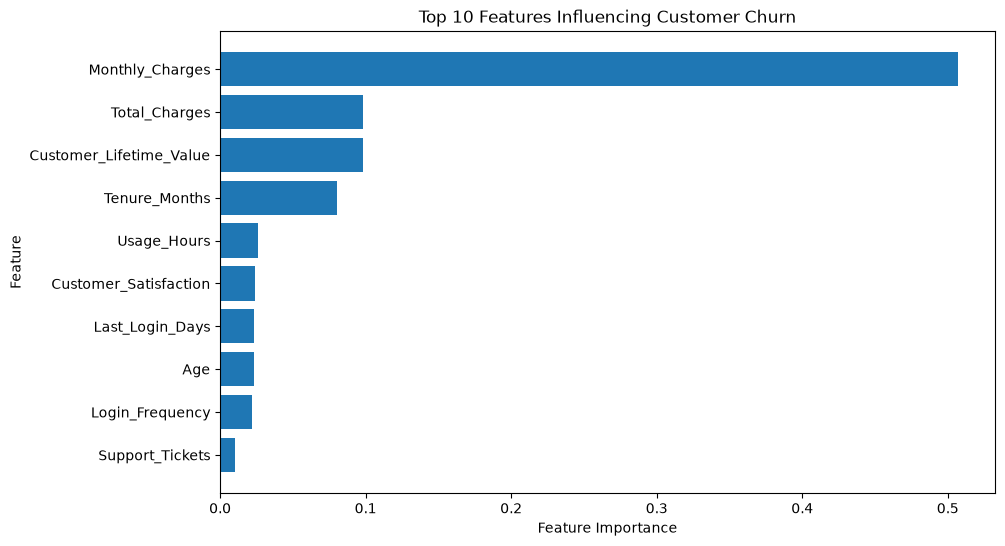

In [107]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features Influencing Customer Churn")

plt.show()

In [108]:
# Display the top 10 features with their importance percentages

top_features = feature_importance.head(10).copy()

top_features["Importance (%)"] = (
    top_features["Importance"] * 100
).round(2)

print("Top 10 Features Influencing Customer Churn:")
print(top_features[["Feature", "Importance (%)"]])

Top 10 Features Influencing Customer Churn:
                    Feature  Importance (%)
2           Monthly_Charges           50.71
3             Total_Charges            9.81
11  Customer_Lifetime_Value            9.80
1             Tenure_Months            8.03
8               Usage_Hours            2.60
9     Customer_Satisfaction            2.43
7           Last_Login_Days            2.35
0                       Age            2.33
4           Login_Frequency            2.16
5           Support_Tickets            1.04


# Churn Probability & Risk Categories

In [109]:
# Generate churn probability for every customer

churn_probability = random_forest_model.predict_proba(X)[:, 1]

df_risk = df_scaled.copy()

df_risk["Churn_Probability"] = churn_probability

df_risk[["Customer_ID", "Churn_Probability"]].head()

,Customer_ID,Churn_Probability
0,CUST10001,0.96
1,CUST10002,0.37
2,CUST10003,0.03
3,CUST10004,0.62
4,CUST10005,0.91


In [110]:
LOW_RISK_THRESHOLD = 0.30
HIGH_RISK_THRESHOLD = 0.70

In [111]:
def assign_risk_level(probability):
    if probability <= LOW_RISK_THRESHOLD:
        return "Low Risk"
    elif probability <= HIGH_RISK_THRESHOLD:
        return "Medium Risk"
    else:
        return "High Risk"


df_risk["Risk_Level"] = df_risk["Churn_Probability"].apply(
    assign_risk_level
)

In [112]:
df_risk["Churn_Probability_Percent"] = (
    df_risk["Churn_Probability"] * 100
).round(2)

df_risk[
    [
        "Customer_ID",
        "Churn_Probability_Percent",
        "Risk_Level"
    ]
].head(10)

,Customer_ID,Churn_Probability_Percent,Risk_Level
0,CUST10001,96.0,High Risk
1,CUST10002,37.0,Medium Risk
2,CUST10003,3.0,Low Risk
3,CUST10004,62.0,Medium Risk
4,CUST10005,91.0,High Risk
5,CUST10006,94.0,High Risk
6,CUST10007,96.0,High Risk
7,CUST10008,39.0,Medium Risk
8,CUST10009,96.0,High Risk
9,CUST10010,0.0,Low Risk


#  Retention Priority

In [113]:
priority_customers = df_risk.sort_values(
    by="Churn_Probability",
    ascending=False
)

priority_customers[
    [
        "Customer_ID",
        "Churn_Probability_Percent",
        "Risk_Level"
    ]
].head(10)

,Customer_ID,Churn_Probability_Percent,Risk_Level
5806,CUST15807,100.0,High Risk
5808,CUST15809,100.0,High Risk
945,CUST10946,100.0,High Risk
962,CUST10963,100.0,High Risk
9320,CUST19321,100.0,High Risk
3666,CUST13667,100.0,High Risk
9918,CUST19919,100.0,High Risk
80,CUST10081,100.0,High Risk
82,CUST10083,100.0,High Risk
58,CUST10059,100.0,High Risk


In [115]:
def assign_retention_priority(risk_level):
    if risk_level == "High Risk":
        return "High Priority"
    elif risk_level == "Medium Risk":
        return "Medium Priority"
    else:
        return "Low Priority"


df_risk["Retention_Priority"] = df_risk["Risk_Level"].apply(
    assign_retention_priority
)

In [116]:
df_risk[
    [
        "Customer_ID",
        "Churn_Probability_Percent",
        "Risk_Level",
        "Retention_Priority"
    ]
].head(10)

,Customer_ID,Churn_Probability_Percent,Risk_Level,Retention_Priority
0,CUST10001,96.0,High Risk,High Priority
1,CUST10002,37.0,Medium Risk,Medium Priority
2,CUST10003,3.0,Low Risk,Low Priority
3,CUST10004,62.0,Medium Risk,Medium Priority
4,CUST10005,91.0,High Risk,High Priority
5,CUST10006,94.0,High Risk,High Priority
6,CUST10007,96.0,High Risk,High Priority
7,CUST10008,39.0,Medium Risk,Medium Priority
8,CUST10009,96.0,High Risk,High Priority
9,CUST10010,0.0,Low Risk,Low Priority


In [117]:
low_value_threshold = df_risk["Customer_Lifetime_Value"].quantile(0.25)
high_value_threshold = df_risk["Customer_Lifetime_Value"].quantile(0.75)

print("Low Value Threshold:", round(low_value_threshold, 2))
print("High Value Threshold:", round(high_value_threshold, 2))

Low Value Threshold: -0.82
High Value Threshold: 0.6


In [118]:
id="r4l2q7"
df_risk["Original_CLV"] = (
    df_risk["Monthly_Charges"] * df_risk["Tenure_Months"]
)

In [120]:
import numpy as np

clv_index = features_to_scale.index("Customer_Lifetime_Value")

clv_mean = scaler.mean_[clv_index]
clv_std = scaler.scale_[clv_index]

df_risk["Original_CLV"] = (
    df_risk["Customer_Lifetime_Value"] * clv_std
) + clv_mean

print(df_risk["Original_CLV"].head())

0    32347.26
1    64723.10
2    18181.50
3     6098.48
4    12590.40
Name: Original_CLV, dtype: float64


In [121]:
low_value_threshold = df_risk["Original_CLV"].quantile(0.25)
high_value_threshold = df_risk["Original_CLV"].quantile(0.75)

print("Low Value Threshold:", round(low_value_threshold, 2))
print("High Value Threshold:", round(high_value_threshold, 2))

Low Value Threshold: 16968.92
High Value Threshold: 73210.63


In [122]:
def assign_customer_value(clv):
    if clv < low_value_threshold:
        return "Low Value"
    elif clv <= high_value_threshold:
        return "Medium Value"
    else:
        return "High Value"


df_risk["Customer_Value"] = df_risk["Original_CLV"].apply(
    assign_customer_value
)

In [123]:
df_risk[
    [
        "Customer_ID",
        "Original_CLV",
        "Customer_Value"
    ]
].head(10)

,Customer_ID,Original_CLV,Customer_Value
0,CUST10001,32347.26,Medium Value
1,CUST10002,64723.10,Medium Value
2,CUST10003,18181.50,Medium Value
3,CUST10004,6098.48,Low Value
4,CUST10005,12590.40,Low Value
5,CUST10006,25386.90,Medium Value
6,CUST10007,73276.72,High Value
7,CUST10008,91316.07,High Value
8,CUST10009,82466.58,High Value
9,CUST10010,13034.88,Low Value


In [124]:
def assign_retention_priority(row):

    if row["Risk_Level"] == "High Risk" and row["Customer_Value"] == "High Value":
        return "Priority 1"

    elif row["Risk_Level"] == "High Risk" and row["Customer_Value"] == "Medium Value":
        return "Priority 2"

    elif row["Risk_Level"] == "Medium Risk" and row["Customer_Value"] == "High Value":
        return "Priority 3"

    else:
        return "Lower Priority"


df_risk["Retention_Priority"] = df_risk.apply(
    assign_retention_priority,
    axis=1
)

In [125]:
df_risk[
    [
        "Customer_ID",
        "Churn_Probability_Percent",
        "Risk_Level",
        "Original_CLV",
        "Customer_Value",
        "Retention_Priority"
    ]
].head(15)

,Customer_ID,Churn_Probability_Percent,Risk_Level,Original_CLV,Customer_Value,Retention_Priority
0,CUST10001,96.0,High Risk,32347.26,Medium Value,Priority 2
1,CUST10002,37.0,Medium Risk,64723.10,Medium Value,Lower Priority
2,CUST10003,3.0,Low Risk,18181.50,Medium Value,Lower Priority
3,CUST10004,62.0,Medium Risk,6098.48,Low Value,Lower Priority
4,CUST10005,91.0,High Risk,12590.40,Low Value,Lower Priority
5,CUST10006,94.0,High Risk,25386.90,Medium Value,Priority 2
6,CUST10007,96.0,High Risk,73276.72,High Value,Priority 1
7,CUST10008,39.0,Medium Risk,91316.07,High Value,Priority 3
8,CUST10009,96.0,High Risk,82466.58,High Value,Priority 1
9,CUST10010,0.0,Low Risk,13034.88,Low Value,Lower Priority


#  Prediction System

In [126]:
def predict_customer_risk(customer_index):

    # Get churn probability
    probability = random_forest_model.predict_proba(
        X.iloc[[customer_index]]
    )[0][1]

    # Assign risk category
    if probability <= LOW_RISK_THRESHOLD:
        risk = "LOW"
    elif probability <= HIGH_RISK_THRESHOLD:
        risk = "MEDIUM"
    else:
        risk = "HIGH"

    # Recommended action
    if risk == "HIGH":
        action = "Retention Team Contact"
    elif risk == "MEDIUM":
        action = "Monitor and Engage Customer"
    else:
        action = "Maintain Regular Engagement"

    return {
        "Customer_ID": df_risk.iloc[customer_index]["Customer_ID"],
        "Churn_Probability": round(probability * 100, 2),
        "Risk": risk,
        "Recommended_Action": action
    }

In [127]:
predict_customer_risk(0)

{'Customer_ID': 'CUST10001',
 'Churn_Probability': np.float64(96.0),
 'Risk': 'HIGH',
 'Recommended_Action': 'Retention Team Contact'}

In [128]:
predict_customer_risk(100)

{'Customer_ID': 'CUST10101',
 'Churn_Probability': np.float64(5.0),
 'Risk': 'LOW',
 'Recommended_Action': 'Maintain Regular Engagement'}

# Business Recommendation Engine

In [129]:
def generate_recommendation(row):
    
    # High churn + low usage
    if row["Risk_Level"] == "High Risk" and row["Usage_Hours"] < 20:
        return "Engagement Campaign"
    
    # High churn + complaints
    elif row["Risk_Level"] == "High Risk" and row["Complaints"] >= 2:
        return "Customer Support Intervention"
    
    # High churn + high charges
    elif row["Risk_Level"] == "High Risk" and row["Monthly_Charges"] > 1500:
        return "Pricing/Discount Review"
    
    # High churn + recent inactivity
    elif row["Risk_Level"] == "High Risk" and row["Last_Login_Days"] > 30:
        return "Re-engagement Campaign"
    
    # Medium risk
    elif row["Risk_Level"] == "Medium Risk":
        return "Monitor and Engage Customer"
    
    # Low risk
    else:
        return "Maintain Regular Engagement"

In [130]:
df_risk["Recommended_Action"] = df_risk.apply(
    generate_recommendation,
    axis=1
)

In [131]:
df_risk[
    [
        "Customer_ID",
        "Churn_Probability_Percent",
        "Risk_Level",
        "Recommended_Action"
    ]
].head(10)

,Customer_ID,Churn_Probability_Percent,Risk_Level,Recommended_Action
0,CUST10001,96.0,High Risk,Engagement Campaign
1,CUST10002,37.0,Medium Risk,Monitor and Engage Customer
2,CUST10003,3.0,Low Risk,Maintain Regular Engagement
3,CUST10004,62.0,Medium Risk,Monitor and Engage Customer
4,CUST10005,91.0,High Risk,Engagement Campaign
5,CUST10006,94.0,High Risk,Engagement Campaign
6,CUST10007,96.0,High Risk,Engagement Campaign
7,CUST10008,39.0,Medium Risk,Monitor and Engage Customer
8,CUST10009,96.0,High Risk,Engagement Campaign
9,CUST10010,0.0,Low Risk,Maintain Regular Engagement


# Customer Risk Report

In [132]:
def identify_key_risk_factor(row):
    
    if row["Risk_Level"] == "Low Risk":
        return "Stable Usage"
    
    elif row["Usage_Hours"] < 20:
        return "Low Usage"
    
    elif row["Complaints"] >= 2:
        return "Complaints"
    
    elif row["Monthly_Charges"] > 1500:
        return "High Charges"
    
    elif row["Last_Login_Days"] > 30:
        return "Recent Inactivity"
    
    elif row["Customer_Satisfaction"] < 5:
        return "Low Satisfaction"
    
    else:
        return "Low Engagement"

In [133]:
df_risk["Key_Risk_Factor"] = df_risk.apply(
    identify_key_risk_factor,
    axis=1
)

In [134]:
customer_risk_report = df_risk[
    [
        "Customer_ID",
        "Churn_Probability_Percent",
        "Risk_Level",
        "Customer_Value",
        "Key_Risk_Factor",
        "Recommended_Action"
    ]
].copy()

In [135]:
customer_risk_report.rename(
    columns={
        "Churn_Probability_Percent": "Churn_Probability"
    },
    inplace=True
)

In [136]:
customer_risk_report.head(10)

,Customer_ID,Churn_Probability,Risk_Level,Customer_Value,Key_Risk_Factor,Recommended_Action
0,CUST10001,96.0,High Risk,Medium Value,Low Usage,Engagement Campaign
1,CUST10002,37.0,Medium Risk,Medium Value,Low Usage,Monitor and Engage Customer
2,CUST10003,3.0,Low Risk,Medium Value,Stable Usage,Maintain Regular Engagement
3,CUST10004,62.0,Medium Risk,Low Value,Low Usage,Monitor and Engage Customer
4,CUST10005,91.0,High Risk,Low Value,Low Usage,Engagement Campaign
5,CUST10006,94.0,High Risk,Medium Value,Low Usage,Engagement Campaign
6,CUST10007,96.0,High Risk,High Value,Low Usage,Engagement Campaign
7,CUST10008,39.0,Medium Risk,High Value,Low Usage,Monitor and Engage Customer
8,CUST10009,96.0,High Risk,High Value,Low Usage,Engagement Campaign
9,CUST10010,0.0,Low Risk,Low Value,Stable Usage,Maintain Regular Engagement


In [139]:
customer_risk_report.to_csv(
    "customer_risk_report.csv",
    index=False
)
print("Customer Risk Report created successfully!")

Customer Risk Report created successfully!


# Model Persistence

In [140]:
import joblib
import os

In [141]:
os.makedirs("models", exist_ok=True)

In [142]:
joblib.dump(
    random_forest_model,
    "models/churn_model.pkl"
)

['models/churn_model.pkl']

In [143]:
joblib.dump(
    scaler,
    "models/scaler.pkl"
)

['models/scaler.pkl']

In [144]:
joblib.dump(
    X.columns.tolist(),
    "models/feature_columns.pkl"
)

['models/feature_columns.pkl']

In [147]:
print(os.listdir("models"))

['churn_model.pkl', 'feature_columns.pkl', 'scaler.pkl']


In [148]:
loaded_model = joblib.load(
    "models/churn_model.pkl"
)

In [149]:
print(type(loaded_model))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [150]:
print(os.listdir("models"))

['churn_model.pkl', 'feature_columns.pkl', 'scaler.pkl']


# Optional Streamlit Interface